<a href="https://colab.research.google.com/github/collinsombati/Machine-Learning/blob/main/Predicting%20rock%20fragmentation%20from%20blasting%20parameters.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


In surface mining and civil engineering, controlling rock fragmentation during blasting is critical for downstream crushing efficiency, material handling, and overall operational safety. Traditional empirical formulas (like the Kuz-Ram model) often fail to capture complex, non-linear relationships between geological properties and blasting design. The goal is to develop a robust machine learning regression model that accurately predicts rock fragmentation size (e.g., mean fragment size or percentage of oversize blocks) based on controllable blasting parameters and rock mass characteristics.Intended AI/ML Outcome: A supervised machine learning regression model (such as Gradient Boosting, Random Forest, or a Multi-Layer Perceptron) deployed via a Google Colab notebook that maps input blasting features to a continuous output of fragment size, enabling engineers to optimize blast designs in advance.
2.
Data Needed

Blasting Design Parameters: Burden, spacing, hole diameter, hole depth, and stemming length.Explosive Properties: Powder factor, maximum charge per delay, and type of explosive used.Geotechnical/Rock Mass Properties: Rock density, uniaxial compressive strength (UCS), Rock Quality Designation (RQD), and joint spacing.Target Output: Measured rock fragmentation metrics (such as mean fragment size $X_{50}$ or fragment size distribution curves obtained through image processing software or sieve analysis).

--- 1. Generating / Loading Dataset ---

First 5 rows of the dataset:


,Burden_m,Spacing_m,Hole_Diameter_mm,Powder_Factor_kg_m3,RQD_pct,UCS_MPa,Mean_Fragment_Size_cm
0,3.123620,4.090220,165,0.652731,77.833626,122.068726,56.355594
1,4.852143,6.117722,140,0.869150,60.639295,105.469233,64.112071
2,4.195982,5.005212,200,0.451517,69.628262,60.805247,72.008402
3,3.795975,5.102317,89,0.515550,68.828754,106.304940,60.270100
4,2.468056,3.221848,200,0.527615,86.642629,155.006431,65.456995



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Burden_m               500 non-null    float64
 1   Spacing_m              500 non-null    float64
 2   Hole_Diameter_mm       500 non-null    int64  
 3   Powder_Factor_kg_m3    500 non-null    float64
 4   RQD_pct                500 non-null    float64
 5   UCS_MPa                500 non-null    float64
 6   Mean_Fragment_Size_cm  500 non-null    float64
dtypes: float64(6), int64(1)
memory usage: 27.5 KB

--- 2. Exploratory Data Analysis & Correlation ---


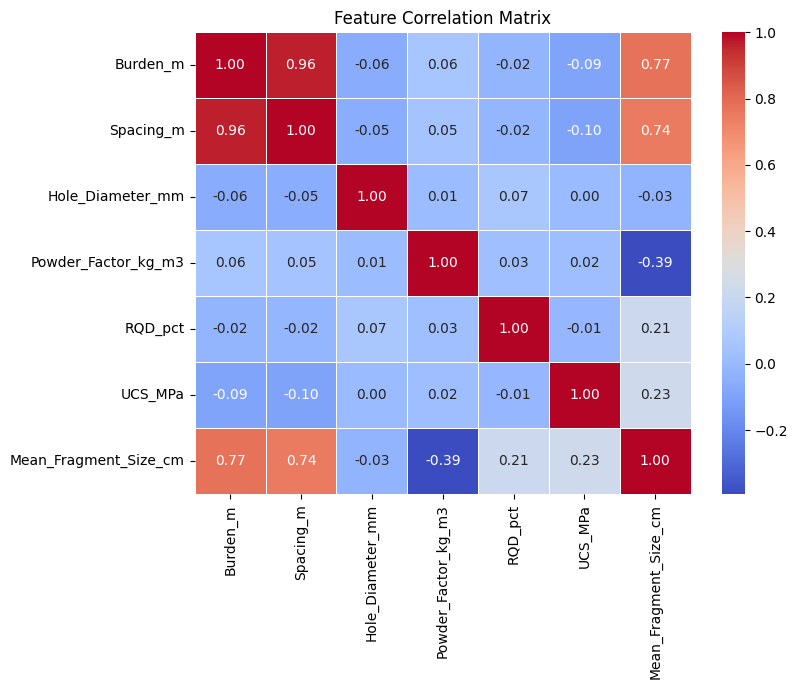


--- 3. Data Preparation & Train-Test Split ---
Training set shape: (400, 6)
Testing set shape: (100, 6)

--- 4. Model Training (Random Forest Regressor) ---
Model training completed successfully!

--- 5. Model Evaluation ---
Root Mean Squared Error (RMSE): 5.01 cm
Mean Absolute Error (MAE): 3.90 cm
R-squared Score ($R^2$): 0.9057

--- 6. Visualizing Results ---


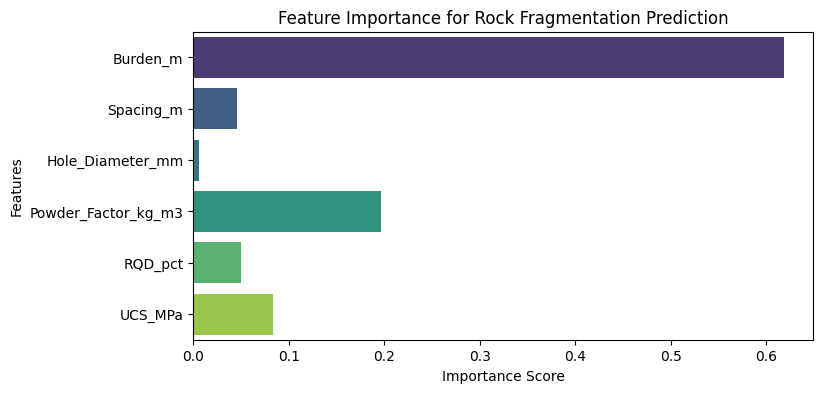

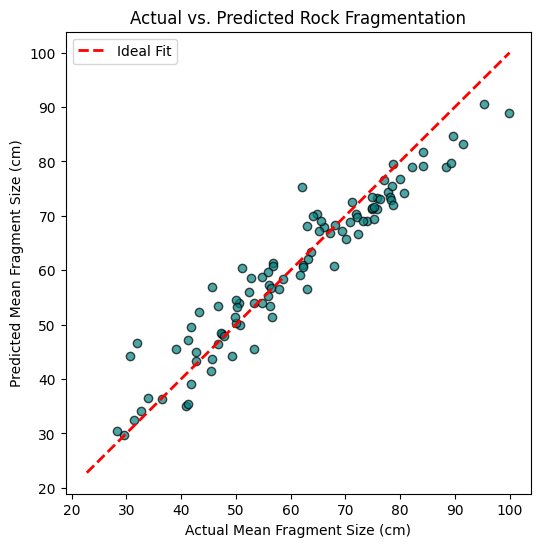

In [2]:
# ==========================================
# AI FOR SCIENCE AND ENGINEERING: PROJECT WORK
# Predicting Rock Fragmentation from Blasting Parameters
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)

print("--- 1. Generating / Loading Dataset ---")
# Simulating a realistic dataset of blast events since proprietary field data is private
# Features: Burden (m), Spacing (m), Hole_Diameter (mm), Powder_Factor (kg/m3), RQD (%), UCS (MPa)
# Target: Mean_Fragment_Size (cm)

n_samples = 500
burden = np.random.uniform(2.0, 5.0, n_samples)
spacing = burden * np.random.uniform(1.1, 1.4, n_samples) # Spacing is usually slightly larger than burden
hole_diameter = np.random.choice([89, 115, 140, 165, 200], n_samples)
powder_factor = np.random.uniform(0.3, 0.9, n_samples)
rqd = np.random.uniform(40, 95, n_samples) # Rock Quality Designation
ucs = np.random.uniform(60, 180, n_samples) # Uniaxial Compressive Strength

# Physics-informed synthetic target relationship:
# Higher powder factor -> smaller fragments; Higher UCS & RQD -> larger fragments; Larger burden -> larger fragments
mean_fragment_size = (
    15.0 * burden
    + 0.15 * ucs
    + 0.25 * rqd
    - 45.0 * powder_factor
    + np.random.normal(0, 3.0, n_samples) # Add some noise
)

# Create DataFrame
df = pd.DataFrame({
    'Burden_m': burden,
    'Spacing_m': spacing,
    'Hole_Diameter_mm': hole_diameter,
    'Powder_Factor_kg_m3': powder_factor,
    'RQD_pct': rqd,
    'UCS_MPa': ucs,
    'Mean_Fragment_Size_cm': mean_fragment_size
})

print("\nFirst 5 rows of the dataset:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\n--- 2. Exploratory Data Analysis & Correlation ---")
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.show()

print("\n--- 3. Data Preparation & Train-Test Split ---")
# Define Features (X) and Target (y)
X = df.drop(columns=['Mean_Fragment_Size_cm'])
y = df['Mean_Fragment_Size_cm']

# Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

print("\n--- 4. Model Training (Random Forest Regressor) ---")
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)
print("Model training completed successfully!")

print("\n--- 5. Model Evaluation ---")
y_pred = model.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f} cm")
print(f"Mean Absolute Error (MAE): {mae:.2f} cm")
print(f"R-squared Score ($R^2$): {r2:.4f}")

print("\n--- 6. Visualizing Results ---")
# Feature Importance Plot
feature_importances = model.feature_importances_
plt.figure(figsize=(8, 4))
sns.barplot(x=feature_importances, y=X.columns, palette='viridis', hue=X.columns, legend=False)
plt.title("Feature Importance for Rock Fragmentation Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

# Actual vs Predicted Plot
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='teal', edgecolor='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label="Ideal Fit")
plt.xlabel("Actual Mean Fragment Size (cm)")
plt.ylabel("Predicted Mean Fragment Size (cm)")
plt.title("Actual vs. Predicted Rock Fragmentation")
plt.legend()
plt.show()

5.Inputs (Features) and Output (Target)Inputs (Features / $X$):

Burden ($m$)Spacing ($m$)Hole Depth ($m$)Powder Factor ($kg/m^3$)Specific Charge ($kg/m^3$)Rock Density ($g/cm^3$)Output (Target / $y$):Mean Fragment Size ($cm$ or $m$) or Percentage of Oversize Rocks ($\%> \text{threshold}$).

6. Proposed ML Workflow


[ Data Collection & Cleaning ]
             │
             ▼

(Handling collinearity between burden, spacing, and powder factor)
             │
             ▼

[ Train-Test Split & Cross-Validation ] (e.g., 80% Training, 20% Testing)
             │
             ▼

[ Model Training & Hyperparameter Tuning ] (Algorithms: Random Forest, XGBoost, Neural Networks)
             │
             ▼

[ Model Evaluation ] (Metrics: RMSE, MAE, $R^2$ Score)
             │
             ▼

[ Deployment & Blasting Optimization ]